In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
Maze = [
    "S...##..",
    "#...##..",
    "##..##..",
    "....####",
    "..#.####",
    "#.#.#.#.",
    ".#.....#",
    ".#.....G"
]
rewards=[]
steps_per_episode=[]

In [4]:
Actions = ["UP","DOWN","LEFT","RIGHT"]

Deltas = [
    (-1,0),
    (1,0),
    (0,1),
    (0,1)
]

Rows = len(Maze)
Columns = len(Maze[0])

Start = (0,0)
Goal =(7,7)

Num_Actions = len(Actions)

In [6]:
Q = np.zeros((Rows,Columns,Num_Actions))

In [12]:
def move(position,action):
  row,col = position
  dr,dc = Deltas[action]
  new_row = row+dr
  new_col = col+dc

  if not(0<=new_row<Rows and 0<=new_col<Columns):
    return position,-5,False

  if(Maze[new_row][new_col]=="#"):
    return position,-5,False

  new_position = (new_row,new_col)

  if new_position == Goal:
    return new_position,100,True

  return new_position,-1,False


In [13]:
Learning_rate = 0.01
Discount_Factor =  0.9
Epsilon = 1.0
Epsilon_Decay = 0.995
Min_Epsilon = 0.01
Episodes = 5000

In [18]:

#Training the agent
for episodes in range(Episodes):
  state = Start
  done = False
  steps = 0
  max_steps = 200
  total_reward =0

  while not done and steps<max_steps:
    row,col = state

    if random.random() < Epsilon:
      action = random.randint(0,Num_Actions-1)
    else:
      action = np.argmax(Q[row,col])

    next_state,reward,done = move(state,action)

    row,col = state
    next_row,next_col = next_state

    old_value = Q[row,col,action]
    next_max = np.max(Q[next_row,next_col])

    Q[row,col,action] = old_value + Learning_rate*(reward + Discount_Factor * next_max * (not done) - old_value)
    state = next_state
    steps += 1
    total_reward += reward

  rewards.append(total_reward)
  steps_per_episode.append(steps)

  Epsilon = max(Epsilon*Epsilon_Decay , Min_Epsilon)
  print("Trainig completed!")
  print("Final Epsilon: ",Epsilon)



Streaming output truncated to the last 5000 lines.
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsilon:  0.01
Trainig completed!
Final Epsi

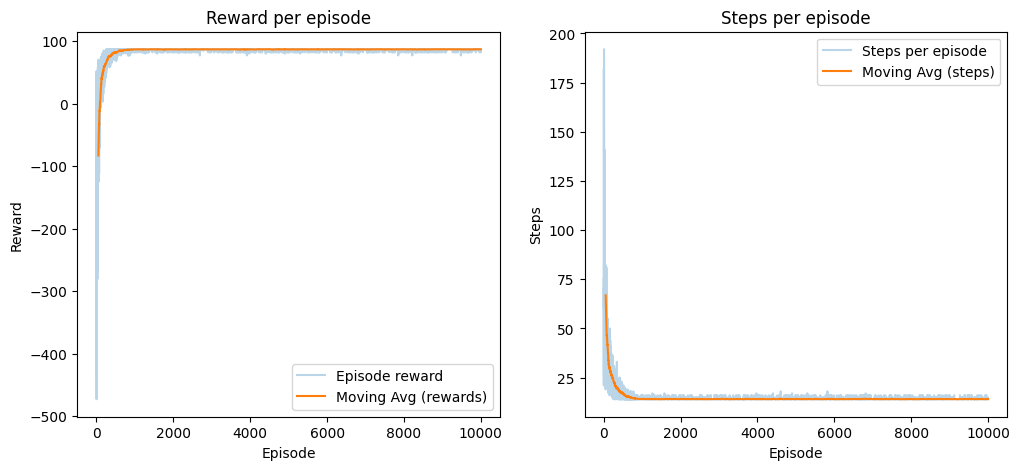

In [21]:
window = 50
moving_avg_rewards = np.convolve(rewards,np.ones(window)/window,mode="valid")
moving_avg_steps = np.convolve(steps_per_episode,np.ones(window)/window,mode="valid")

fig,axes = plt.subplots(1,2,figsize=(12,5))

axes[0].plot(rewards,alpha=0.3,label="Episode reward")
axes[0].plot(range(window-1,len(rewards)),moving_avg_rewards,label="Moving Avg (rewards)")
axes[0].set_title("Reward per episode")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Reward")
axes[0].legend()

axes[1].plot(steps_per_episode,alpha=0.3,label="Steps per episode")
axes[1].plot(range(window-1,len(steps_per_episode)),moving_avg_steps,label="Moving Avg (steps)")
axes[1].set_title("Steps per episode")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Steps")
axes[1].legend()

In [29]:
#find the path
state = Start
path = [state]
visited = {state} #set to ensire the agent does not revist the point

for _ in range(Rows*Columns*4):
  if state == Goal:
    break

  row,col = state
  action = np.argmax(Q[row,col])

  next_state,reward,done = move(state,action)

  if next_state == state or next_state in visited:
    print("Agent got stuck or entered a loop")
    break

  state = next_state
  path.append(state)
  visited.add(state)

if path[-1] == Goal:
    print("Goal reached")
    print("Path length : ", len(path)-1)
    print("Path: ",path)
else:
    print("Goal not reached try training for more episodes")


Goal reached
Path length :  14
Path:  [(0, 0), (0, 1), (1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (4, 3), (5, 3), (6, 3), (6, 4), (6, 5), (6, 6), (7, 6), (7, 7)]


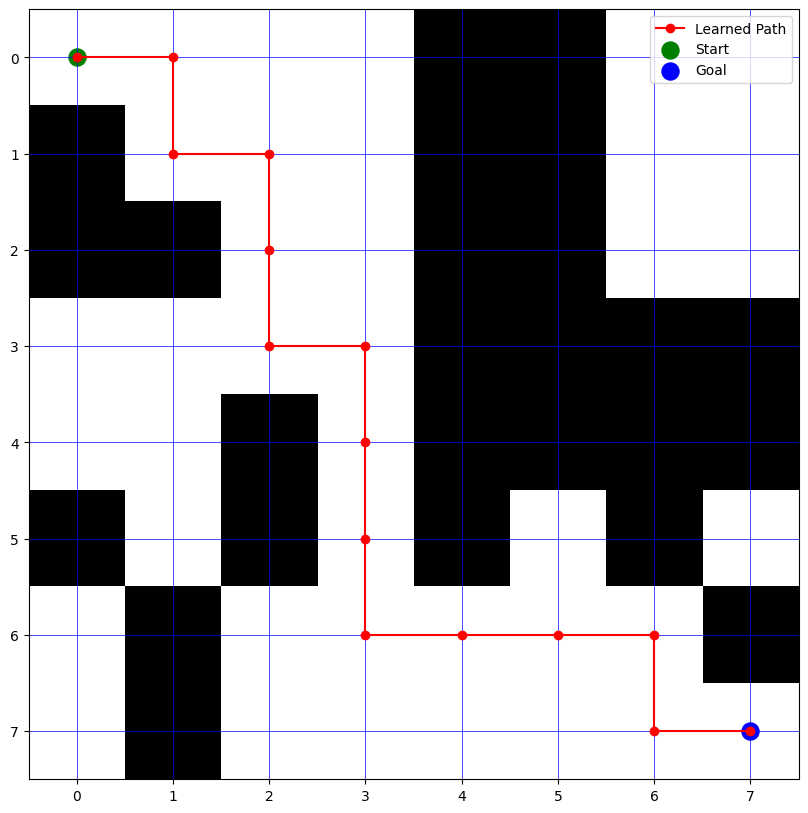

In [41]:
grid = np.zeros((Rows,Columns))

for r in range(Rows):
  for c in range(Columns):
    if Maze[r][c]=="#":
      grid[r,c]=1

plt.figure(figsize=(10,10))
plt.imshow(grid,cmap="gray_r")

plt.xticks(range(Columns))
plt.yticks(range(Rows))
plt.grid(True,color="blue",linewidth=0.5)

if path:
  path_rows = [p[0] for p in path]
  path_cols = [p[1] for p in path]
  plt.plot(path_cols,path_rows,"ro-",label="Learned Path")

plt.scatter(Start[1],Start[0],color="green",label="Start",s=150)
plt.scatter(Goal[1],Goal[0],color="blue",label="Goal",s=150)
plt.legend()
plt.show()